# Reading a band-like structure on a multi-sequence MR study

**DICOM geometry, contrast classes, survey sheets, a read ledger, and a gap measured in millimetres**

Tendons, ligaments, nerves and fasciae are thin bands that are judged
*along their length*: is the band continuous, what fills an interruption,
how long is the defect, and how far is it from the point where the band
attaches to bone? Answering that from a clinical MR examination needs
several things that are easy to get subtly wrong:

* **geometry** — every image of a DICOM series carries its own position and
  orientation in a patient coordinate system; planes, slice order and
  millimetres must come from those tags, not from the series description,
  the instance number or a pixel count;
* **contrast** — the same tissue is bright on one sequence and dark on
  another; which series is *fluid-sensitive* follows from the timing
  parameters TR / TE / TI;
* **a systematic look** — every region on every slice, recorded in a
  ledger, so that the finding reported is the one most views agree on;
* **a measurement** — the defect ends and the attachment placed on the
  image and converted to patient millimetres.

`ov.radiology` provides one function per step:

| Step | Functions |
|---|---|
| index a study, planes, contrast classes | `read_dicom_study`, `plane_of`, `sequence_weighting` |
| images for reading | `render_slices`, `montage`, `region_sheets` |
| systematic survey + reader ledger | `structure_survey`, `sheet_cell_to_patient`, `ledger_add_read`, `ledger_hotspots`, `ledger_concordance`, `ledger_principal`, `draft_principal` |
| signal along the band | `path_profile`, `abnormal_segments`, `profile_slices`, `measure_band_gap` |
| measurement | `landmark_measurement` |

**Data.** No patient images are used. We build a **synthetic MR phantom**
— soft tissue, fat, two bone blocks with fatty marrow and a cortical shell,
a band ("tendon") that runs into the lower bone block, an 18 mm defect in
the band filled with fluid, oedema in the neighbouring fat, and a small
joint effusion as a distractor — and "scan" it with five series
(sagittal T1, sagittal STIR with anisotropic pixels, axial fat-suppressed
PD, an oblique coronal T2 and a three-plane localizer). Signal comes from
the spin-echo / inversion-recovery equations, with partial-volume averaging
and Rician noise, and every series is written as real DICOM files with
`pydicom`. Because we made the phantom, every number the pipeline produces
can be checked against the truth.

In [1]:
import io
import json
import os
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from PIL import Image as PILImage

import pydicom
from pydicom.dataset import Dataset, FileMetaDataset
from pydicom.uid import ExplicitVRLittleEndian, generate_uid

import omicverse as ov

T0 = time.time()
rng = np.random.default_rng(7)
WORK = 'radiology_phantom'
shutil.rmtree(WORK, ignore_errors=True)
os.makedirs(WORK)
print('pydicom', pydicom.__version__)


def show(path, max_px=900):
    """Display a rendered sheet, downscaled for the notebook (the file keeps full size)."""
    im = PILImage.open(path)
    im.thumbnail((max_px, max_px))
    buf = io.BytesIO()
    im.convert('RGB').save(buf, format='PNG')
    display(Image(data=buf.getvalue()))

pydicom 2.4.4


## 1. Principle

### 1.1 Patient coordinates

DICOM places every pixel in one patient-based coordinate system, **LPS**:
$+x$ toward the patient's **L**eft, $+y$ toward **P**osterior, $+z$ toward
**S**uperior, in millimetres. Each image carries

* `ImagePositionPatient` (IPP) — the centre of the first (top-left) pixel,
* `ImageOrientationPatient` (IOP) — two unit vectors: $\mathbf{r}$, the
  direction along a row (increasing column index), and $\mathbf{c}$, the
  direction down a column (increasing row index),
* `PixelSpacing` $=(\Delta_r, \Delta_c)$ — **row spacing first** (distance
  between rows), then column spacing.

The patient position of pixel (row $i$, column $j$) is (DICOM PS3.3 C.7.6.2.1.1)

$$\mathbf{P}(i,j) = \mathrm{IPP} + j\,\Delta_c\,\mathbf{r} + i\,\Delta_r\,\mathbf{c}.$$

The **slice normal** $\mathbf{n} = \mathbf{r}\times\mathbf{c}$ names the
plane: the patient axis it is most aligned with ($x$ → sagittal, $y$ →
coronal, $z$ → axial). Slices are ordered by $\mathbf{n}\cdot\mathrm{IPP}$,
not by instance number. A finding seen on one series is found on another by
projecting its patient point onto that series' slices; distances are
Euclidean distances between patient points, so they are correct across
series of different resolution and on oblique planes.

### 1.2 Contrast from TR, TE, TI

For a spin-echo sequence with repetition time TR and echo time TE, a tissue
with proton density $\rho$ and relaxation times $T_1$, $T_2$ gives

$$S_{\mathrm{SE}} = \rho\,(1-e^{-\mathrm{TR}/T_1})\,e^{-\mathrm{TE}/T_2},$$

and an inversion-recovery sequence (STIR) with inversion time TI

$$S_{\mathrm{IR}} = \rho\,\left|1-2e^{-\mathrm{TI}/T_1}+e^{-\mathrm{TR}/T_1}\right|\,e^{-\mathrm{TE}/T_2}.$$

Short TR and short TE (**T1-weighted**): fat bright, fluid dark — anatomy,
marrow. Long TR, short TE: **proton density**. Long TE: **T2** — fluid
bright. STIR with $\mathrm{TI}\approx T_1^{\mathrm{fat}}\ln 2$ nulls fat;
fluid and oedema stay bright. Fluid-sensitive series (fat-suppressed PD/T2,
STIR) are where most lesions show; T1 shows the band as a dark line against
bright fat. A normal tendon has a very short $T_2$ and is dark on every
sequence.

### 1.3 The gap criterion

Along the band, the defect is where the band's own dark signal is lost on
the anatomic image **and** fluid signal is high on the fluid-sensitive one.
With $s(\ell)$ the signal at arc length $\ell$ and $\tilde s$ its median
over the intact band, `measure_band_gap` scores

$$g(\ell)=\min\!\left(\frac{s_{\mathrm{anat}}(\ell)/\tilde s_{\mathrm{anat}}}{f_{\mathrm{anat}}},\;
  \frac{s_{\mathrm{fluid}}(\ell)/\tilde s_{\mathrm{fluid}}}{f_{\mathrm{fluid}}}\right)$$

and takes the longest run with $g\ge 1$ (defaults $f_{\mathrm{anat}}=1.5$,
$f_{\mathrm{fluid}}=2$). The comparison is internal — the band against
itself on the same image — so scanner gain and windowing cancel.

## 2. Build the phantom

Tissues get textbook-order relaxation values at 1.5 T. The geometry is
defined analytically in patient millimetres; the label function below is
the **ground truth**. The defect runs from $z=62$ to $z=80$ mm on the
band's midline (18 mm) and lengthens slightly toward the band's edges,
as real tear ends are rarely flat; the band attaches to the top of the
lower bone block at $z=28$ mm.

In [2]:
AIR, MUSCLE, FAT, MARROW, CORTEX, TENDON, GAP, EFFUSION, EDEMA = range(9)
NAMES = ['air', 'muscle', 'fat', 'marrow', 'cortex', 'tendon', 'gap fluid', 'effusion', 'oedema']
#               rho   T1(ms) T2(ms) fat-containing
TISSUE = {AIR:    (0.0,  1000,   1, False),
          MUSCLE: (0.80,  870,  45, False),
          FAT:    (1.00,  260,  80, True),
          MARROW: (0.95,  300,  80, True),
          CORTEX: (0.05, 1000,   1, False),
          TENDON: (0.40,  500,   8, False),
          GAP:    (1.00, 2500, 800, False),
          EFFUSION: (1.00, 2500, 800, False),
          EDEMA:  (0.85, 1100,  70, False)}

BAND_Y, BAND_HALF_T, BAND_HALF_W = 42.0, 3.0, 7.0     # band centre (y), half thickness, half width (mm)
GAP_Z1, GAP_Z2, ATTACH_Z = 62.0, 80.0, 28.0          # defect ends on the midline, attachment level


def gap_ends(x):
    """Defect ends (z) at lateral position x: 18 mm on the midline, ~1 mm longer at the edges."""
    w = 0.6 * (np.asarray(x) / BAND_HALF_W) ** 2
    return GAP_Z1 - w, GAP_Z2 + w


def labels(P):
    """Ground-truth tissue label at patient points P[..., 3] (LPS mm)."""
    x, y, z = P[..., 0], P[..., 1], P[..., 2]
    lab = np.full(x.shape, AIR, np.int8)
    e = (x / 40) ** 2 + (y / 52) ** 2
    body = (e <= 1) & (z > -5)
    lab[body] = MUSCLE
    lab[body & (e > 0.81)] = FAT                                       # subcutaneous fat
    lab[body & (np.abs(x) < 16) & (y > 44)] = FAT                      # fat behind the band
    lab[(np.abs(x) < 15) & (y > 20) & (y < 39) & (z > 30) & (z < 125)] = FAT   # fat pad in front of it
    lab[(np.abs(x) < 10) & (y > 30) & (y < 39) & (z > 56) & (z < 86)] = EDEMA  # oedema in the fat pad
    # upper bone: cylinder with cortex, from z = 40 up
    rr = np.hypot(x, y + 5)
    shaft = (rr < 14) & (z > 40)
    lab[shaft] = CORTEX
    lab[shaft & (rr < 12) & (z > 42)] = MARROW
    # lower bone block (rounded box) with a 1.5 mm cortical shell, z 0..28
    se = (x / 25) ** 4 + ((y - 5) / 40) ** 4
    blk = (se <= 1) & (z > 0) & (z < ATTACH_Z)
    lab[blk] = CORTEX
    lab[blk & ((x / 23.5) ** 4 + ((y - 5) / 38.5) ** 4 <= 1) & (z > 1.5) & (z < ATTACH_Z - 1.5)] = MARROW
    lab[(np.abs(x) < 12) & (y > -25) & (y < -10) & (z > 29.5) & (z < 38.5)] = EFFUSION  # joint effusion
    # the band, running into the top of the lower block
    band = (np.abs(x) < BAND_HALF_W) & (np.abs(y - BAND_Y) < BAND_HALF_T) & (z >= ATTACH_Z)
    lab[band] = TENDON
    z1, z2 = gap_ends(x)
    lab[(np.abs(x) < BAND_HALF_W + 0.6) & (np.abs(y - BAND_Y) < BAND_HALF_T + 0.6)
        & (z > z1) & (z < z2)] = GAP
    return lab

Signal per tissue and sequence from the equations of §1.2. Spectral fat
suppression (as in "PD FS") is modelled by scaling fat-containing tissues
to 20 % — suppression is never complete in practice.

In [3]:
def tissue_signal(seq):
    out = np.zeros(len(TISSUE))
    for k, (rho, t1, t2, fatty) in TISSUE.items():
        TR, TE, TI = seq['TR'], seq['TE'], seq.get('TI')
        if TI:
            s = rho * abs(1 - 2 * np.exp(-TI / t1) + np.exp(-TR / t1)) * np.exp(-TE / t2)
        else:
            s = rho * (1 - np.exp(-TR / t1)) * np.exp(-TE / t2)
        if seq.get('fatsat') and fatty:
            s *= 0.20
        out[k] = s
    return out


SEQS = {'T1':    dict(TR=550, TE=12),
        'STIR':  dict(TR=4000, TE=40, TI=170),
        'PDFS':  dict(TR=2500, TE=30, fatsat=True),
        'T2':    dict(TR=3500, TE=85),
        'LOC':   dict(TR=20, TE=5)}
contrast = pd.DataFrame({k: tissue_signal(v) for k, v in SEQS.items()}, index=NAMES).round(3)
contrast

              T1   STIR   PDFS     T2    LOC
air        0.000  0.000  0.000  0.000  0.000
muscle     0.287  0.209  0.388  0.119  0.016
fat        0.757  0.024  0.137  0.346  0.070
marrow     0.687  0.078  0.131  0.328  0.058
cortex     0.000  0.000  0.000  0.000  0.000
tendon     0.060  0.001  0.009  0.000  0.008
gap fluid  0.195  0.634  0.609  0.677  0.008
effusion   0.195  0.634  0.609  0.677  0.008
oedema     0.282  0.330  0.497  0.242  0.014

The table is the whole contrast story: on **T1** fat (0.76) and marrow are
bright, fluid dark-grey (0.20), the tendon nearly black; on **STIR** fat
and marrow are nulled while fluid (0.63) and oedema are the brightest
tissues; on **PD FS** fat is suppressed to a dark grey and fluid is bright;
on the non-suppressed **T2** fluid is
brightest but fat stays moderately bright. The tendon is dark on all of
them — a band that is *not* dark is abnormal.

Next, the five series. Each is a list of slices with its own IPP / IOP /
pixel spacing. The sagittal STIR deliberately has **anisotropic pixels**
(0.8 mm between rows, 0.6 mm between columns), its instance numbers run
**opposite** to slice position, and the coronal series is **oblique**
(tilted 12°) and has a description without any contrast keyword.

In [4]:
def sag(xs, ps, z_top=150.0, y0=-60.0, fov=(160.0, 120.0)):
    """Sagittal slices: rows run inferior (-z), columns run posterior (+y)."""
    r, c = np.array([0, 1.0, 0]), np.array([0, 0, -1.0])
    return [dict(ipp=np.array([x, y0, z_top]), r=r, c=c) for x in xs], ps, \
        (int(round(fov[0] / ps[0])), int(round(fov[1] / ps[1])))


def axial(zs, ps, fov=(120.0, 80.0)):
    r, c = np.array([1.0, 0, 0]), np.array([0, 1.0, 0])
    return [dict(ipp=np.array([-40.0, -60.0, z]), r=r, c=c) for z in zs], ps, \
        (int(round(fov[0] / ps[0])), int(round(fov[1] / ps[1])))


def coronal_oblique(offsets, ps, tilt_deg=12.0, centre=(0.0, 37.0, 70.0), fov=(170.0, 80.0)):
    a = np.deg2rad(tilt_deg)
    r, c = np.array([1.0, 0, 0]), np.array([0, np.sin(a), -np.cos(a)])
    n = np.cross(r, c)
    sl = []
    for d in offsets:
        ctr = np.asarray(centre) + d * n
        sl.append(dict(ipp=ctr - r * fov[1] / 2 - c * fov[0] / 2, r=r, c=c))
    return sl, ps, (int(round(fov[0] / ps[0])), int(round(fov[1] / ps[1])))


SAG_X = np.arange(-12, 12.1, 3.0)
SERIES = [
    # description, seq, geometry, slice thickness, series number, reverse instance numbers
    ('Sag T1',   'T1',   sag(SAG_X, (0.6, 0.6)), 3.0, 2, False),
    ('Sag STIR', 'STIR', sag(SAG_X, (0.8, 0.6)), 3.0, 3, True),
    ('Ax PD FS', 'PDFS', axial(np.arange(10, 131, 4.0), (0.5, 0.5)), 3.5, 4, False),
    ('COR obl',  'T2',   coronal_oblique(np.arange(-15, 15.1, 3.0), (0.7, 0.7)), 3.0, 5, False),
]
pd.DataFrame([(d, s, len(g[0]), g[1], g[2], th) for d, s, g, th, _, _ in SERIES],
             columns=['description', 'sequence', 'n_slices', 'pixel_spacing (row, col) mm', 'rows x cols', 'thickness mm'])

  description sequence  n_slices pixel_spacing (row, col) mm rows x cols  \
0      Sag T1       T1         9                  (0.6, 0.6)  (267, 200)   
1    Sag STIR     STIR         9                  (0.8, 0.6)  (200, 200)   
2    Ax PD FS     PDFS        31                  (0.5, 0.5)  (240, 160)   
3     COR obl       T2        11                  (0.7, 0.7)  (243, 114)   

   thickness mm  
0           3.0  
1           3.0  
2           3.5  
3           3.0  

**Image formation.** Each pixel averages the ground truth over a 2 × 2
in-plane and 3-point through-slice sub-grid (partial volume: a pixel that
straddles the band edge is a mixture), then gets **Rician** noise — the
magnitude of a complex signal with Gaussian noise in both channels, as in
any magnitude MR image.

In [5]:
def image(sl, ps, shape, seq, thickness):
    sig = tissue_signal(SEQS[seq])
    n = np.cross(sl['r'], sl['c'])
    rr, cc = np.mgrid[0:shape[0], 0:shape[1]].astype(float)
    acc = np.zeros(shape)
    subs = [(dr, dc, dt) for dr in (-0.25, 0.25) for dc in (-0.25, 0.25) for dt in (-thickness / 3, 0, thickness / 3)]
    for dr, dc, dt in subs:
        P = (sl['ipp'] + ((cc + dc) * ps[1])[..., None] * sl['r'] + ((rr + dr) * ps[0])[..., None] * sl['c']
             + dt * n)
        acc += sig[labels(P)]
    clean = acc / len(subs)
    sigma = 0.015
    noisy = np.hypot(clean + rng.normal(0, sigma, shape), rng.normal(0, sigma, shape))
    return np.clip(noisy * 2500, 0, 65535).astype(np.uint16)


STUDY_DIR = os.path.join(WORK, 'study')
STUDY_UID, FOR_UID = generate_uid(), generate_uid()


def write_series(desc, seq, geom, thickness, number, reverse, image_type='ORIGINAL\\PRIMARY\\M'):
    """Render and write one series; `geom` = (slices, pixel spacing, shape) or a list of such triples."""
    triples = [(sl, geom[1], geom[2]) for sl in geom[0]] if isinstance(geom, tuple) else geom
    suid = generate_uid()
    d = os.path.join(STUDY_DIR, f'S{number:02d}')
    os.makedirs(d, exist_ok=True)
    p = SEQS[seq]
    n = len(triples)
    for k, (sl, ps, shape) in enumerate(triples):
        px = image(sl, ps, shape, seq, thickness)
        ds = Dataset()
        ds.file_meta = FileMetaDataset()
        ds.file_meta.TransferSyntaxUID = ExplicitVRLittleEndian
        ds.file_meta.MediaStorageSOPClassUID = '1.2.840.10008.5.1.4.1.1.4'      # MR Image Storage
        sop = generate_uid()
        ds.file_meta.MediaStorageSOPInstanceUID = sop
        ds.SOPClassUID, ds.SOPInstanceUID = '1.2.840.10008.5.1.4.1.1.4', sop
        ds.PatientName, ds.PatientID = 'PHANTOM^SYNTHETIC', 'PHANTOM-0001'
        ds.StudyInstanceUID, ds.SeriesInstanceUID, ds.FrameOfReferenceUID = STUDY_UID, suid, FOR_UID
        ds.StudyDescription, ds.BodyPartExamined = 'Synthetic band phantom', 'EXTREMITY'
        ds.Modality, ds.MagneticFieldStrength = 'MR', 1.5
        ds.SeriesDescription, ds.SeriesNumber = desc, number
        ds.InstanceNumber = (n - k) if reverse else (k + 1)
        ds.ImageType = image_type.split('\\')
        ds.Laterality = 'R'
        ds.ScanningSequence = 'IR' if p.get('TI') else 'SE'
        ds.RepetitionTime, ds.EchoTime = p['TR'], p['TE']
        if p.get('TI'):
            ds.InversionTime = p['TI']
        ds.SliceThickness = thickness
        ds.ImageOrientationPatient = [float(v) for v in np.r_[sl['r'], sl['c']]]
        ds.ImagePositionPatient = [round(float(v), 4) for v in sl['ipp']]
        ds.PixelSpacing = [float(ps[0]), float(ps[1])]
        ds.Rows, ds.Columns = px.shape
        ds.SamplesPerPixel, ds.PhotometricInterpretation = 1, 'MONOCHROME2'
        ds.BitsAllocated = ds.BitsStored = 16
        ds.HighBit, ds.PixelRepresentation = 15, 0
        ds.RescaleSlope, ds.RescaleIntercept = 1, 0
        ds.PixelData = px.tobytes()
        ds.is_little_endian, ds.is_implicit_VR = True, False
        ds.save_as(os.path.join(d, f'IM{k:04d}.dcm'), write_like_original=False)


t = time.time()
for args in SERIES:
    write_series(*args)
# a three-plane localizer is ONE series whose images have different orientations
loc = [(sag([0.0], (2.5, 2.5))[0][0], (2.5, 2.5), (64, 48)),
       (coronal_oblique([0.0], (2.5, 2.5), tilt_deg=0)[0][0], (2.5, 2.5), (68, 32)),
       (axial([70.0], (2.5, 2.5))[0][0], (2.5, 2.5), (48, 32))]
write_series('Localizer', 'LOC', loc, 8.0, 1, False, image_type='ORIGINAL\\PRIMARY\\LOCALIZER')
# exported studies often contain non-image files
with open(os.path.join(STUDY_DIR, 'README.txt'), 'w') as f:
    f.write('synthetic phantom export\n')
print(f'wrote DICOM in {time.time() - t:.1f} s:', sorted(os.listdir(STUDY_DIR)),
      sum(len(fs) for _, _, fs in os.walk(STUDY_DIR)), 'files')

wrote DICOM in 10.3 s: ['README.txt', 'S01', 'S02', 'S03', 'S04', 'S05'] 64 files


Ground truth on the band's midline (sagittal plane $x=0$), straight from
the label function:

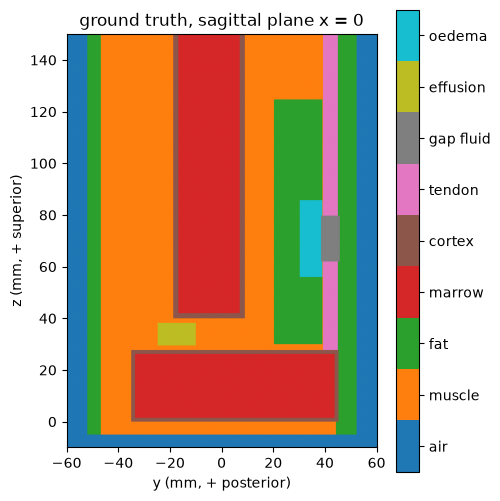

true gap on the midline: 18.0 mm; midpoint [ 0. 42. 71.]; midpoint-to-attachment 43.0 mm


In [6]:
zz, yy = np.mgrid[150:-10:-0.25, -60:60:0.25]
mid = labels(np.stack([np.zeros_like(yy), yy, zz], -1))
fig, ax = plt.subplots(figsize=(5, 6))
cmap = plt.get_cmap('tab10', len(NAMES))
im = ax.imshow(mid, cmap=cmap, vmin=-0.5, vmax=len(NAMES) - 0.5, extent=(-60, 60, -10, 150))
cb = fig.colorbar(im, ax=ax, ticks=range(len(NAMES)))
cb.ax.set_yticklabels(NAMES)
ax.set_xlabel('y (mm, + posterior)')
ax.set_ylabel('z (mm, + superior)')
ax.set_title('ground truth, sagittal plane x = 0')
plt.show()
TRUE_GAP = GAP_Z2 - GAP_Z1
TRUE_MID = np.array([0.0, BAND_Y, (GAP_Z1 + GAP_Z2) / 2])
TRUE_ATTACH = np.array([0.0, BAND_Y, ATTACH_Z])
print(f'true gap on the midline: {TRUE_GAP:.1f} mm; midpoint {TRUE_MID}; '
      f'midpoint-to-attachment {np.linalg.norm(TRUE_MID - TRUE_ATTACH):.1f} mm')

## 3. Index the study: planes, contrast classes, slice order

`read_dicom_study` reads every file under the folder (headers only), groups
instances by `SeriesInstanceUID`, sorts each series along its slice normal
and classifies it. `study.table()` is the overview a reader starts from.

In [7]:
st = ov.radiology.read_dicom_study(STUDY_DIR)
print('skipped (not DICOM images):', [os.path.basename(p) for p in st.skipped])
print('laterality:', st.laterality())
st.table()[['series_number', 'description', 'plane', 'weighting', 'is_localizer', 'n_instances',
            'pixel_spacing_mm', 'slice_spacing_mm', 'normal']]

skipped (not DICOM images): ['README.txt']
laterality: right


   series_number description  plane        weighting  is_localizer  \
0              2      Sag T1    SAG               T1         False   
1              3    Sag STIR    SAG  fluid_sensitive         False   
2              4    Ax PD FS     AX  fluid_sensitive         False   
3              5     COR obl    COR  fluid_sensitive         False   
4              1   Localizer  MIXED               T1          True   

   n_instances pixel_spacing_mm  slice_spacing_mm                normal  
0            9        0.6 x 0.6               3.0      [-1.0, 0.0, 0.0]  
1            9        0.8 x 0.6               3.0      [-1.0, 0.0, 0.0]  
2           31        0.5 x 0.5               4.0       [0.0, 0.0, 1.0]  
3           11        0.7 x 0.7               3.0  [-0.0, 0.978, 0.208]  
4            3        2.5 x 2.5              20.0      [-1.0, 0.0, 0.0]  

Every row agrees with how the series were built:

* planes come from the normals: $(-1,0,0)$ → SAG, $(0,0,1)$ → AX, and the
  12°-tilted $(0, 0.978, 0.208)$ → COR — although its description says
  nothing but "COR obl";
* the three-plane localizer is flagged (description, `ImageType`, and
  mixed planes in one series) and its plane reported as `MIXED`;
* `COR obl` has no contrast keyword; its TE of 85 ms classifies it as
  fluid-sensitive (§1.2); STIR is fluid-sensitive from its inversion time;
  `Ax PD FS` from the "FS" keyword;
* the README is listed in `skipped`, laterality comes from the
  `Laterality` tag.

`plane_of` and `sequence_weighting` are the two classifiers used inside,
and can be called directly:

In [8]:
c30, s30 = np.cos(np.deg2rad(30)), np.sin(np.deg2rad(30))
c50, s50 = np.cos(np.deg2rad(50)), np.sin(np.deg2rad(50))
iops = {'sagittal':                   [0, 1, 0, 0, 0, -1],
        'coronal':                    [1, 0, 0, 0, 0, -1],
        'axial':                      [1, 0, 0, 0, 1, 0],
        'axial tilted 30 deg':        [1, 0, 0, 0, c30, -s30],
        'axial tilted 50 deg (!)':    [1, 0, 0, 0, c50, -s50]}
for name, iop in iops.items():
    n = np.cross(iop[:3], iop[3:])
    print(f'{name:28s} normal={np.round(n, 2)} -> {ov.radiology.plane_of(iop)}')

sagittal                     normal=[-1  0  0] -> SAG
coronal                      normal=[0 1 0] -> COR
axial                        normal=[0 0 1] -> AX
axial tilted 30 deg          normal=[-0.    0.5   0.87] -> AX
axial tilted 50 deg (!)      normal=[-0.    0.77  0.64] -> COR


A slice tilted past 45° from axial is, geometrically, closer to coronal —
`plane_of` says so, whatever the protocol called it.

In [9]:
cases = [('', 550, 12, np.nan, 'SE'), ('', 2500, 30, np.nan, 'SE'), ('', 3500, 85, np.nan, 'SE'),
         ('', 4000, 40, 170, 'IR'), ('Sag STIR', np.nan, np.nan, np.nan, ''),
         ('Ax PD FS', 2500, 30, np.nan, 'SE'), ('Cor T1 FS post', 550, 12, np.nan, 'SE')]
pd.DataFrame([dict(description=d, TR=tr, TE=te, TI=ti,
                   weighting=ov.radiology.sequence_weighting(d, te=te, tr=tr, ti=ti, scanning_sequence=sq))
              for d, tr, te, ti, sq in cases])

      description      TR    TE     TI        weighting
0                   550.0  12.0    NaN               T1
1                  2500.0  30.0    NaN               PD
2                  3500.0  85.0    NaN  fluid_sensitive
3                  4000.0  40.0  170.0  fluid_sensitive
4        Sag STIR     NaN   NaN    NaN  fluid_sensitive
5        Ax PD FS  2500.0  30.0    NaN  fluid_sensitive
6  Cor T1 FS post   550.0  12.0    NaN  fluid_sensitive

Timing alone gives T1 / PD / fluid-sensitive as expected; an inversion
time or an `IR` scanning sequence means fluid-sensitive. Keywords take
precedence — note the last row: a *fat-suppressed T1* (e.g. after
contrast) is labelled fluid-sensitive because of "FS", although fluid is
dark on it. The class is a starting point; check it on the image (is fluid
bright?) before relying on it.

**Geometry in use.** Both sagittal series have the same slice positions,
but their instance numbers were written in opposite directions. Each
series is sorted by the position along its own normal,
$\mathbf{n}\cdot\mathrm{IPP}$; here $\mathbf{n}=(-1,0,0)$ points to the
patient's right, so "first" is the most *left* slice ($x=+12$). Never pair
slices of two series by instance number — pair them by patient position.
A patient point maps to the nearest slice of every series, which is how one
location is cited on all of them.

In [10]:
stir, t1, ax, cor = st['Sag STIR'], st['Sag T1'], st['Ax PD FS'], st['COR obl']
print('Sag T1   instance numbers in slice order:', t1.instance_numbers)
print('Sag STIR instance numbers in slice order:', stir.instance_numbers)
print(stir.slice_positions().head(3).assign(x_mm=lambda d: [stir.center_of(i)[0] for i in d.instance_number]))
print('\nnearest instance of every series to the true defect midpoint', TRUE_MID)
st.nearest_instances(TRUE_MID)[['description', 'plane', 'instance_number', 'row', 'col', 'out_of_plane_mm', 'inside']].round(2)

Sag T1   instance numbers in slice order: [9, 8, 7, 6, 5, 4, 3, 2, 1]
Sag STIR instance numbers in slice order: [1, 2, 3, 4, 5, 6, 7, 8, 9]
   instance_number                                   sop_instance_uid  \
0                1  1.2.826.0.1.3680043.8.498.48613578068334249108...   
1                2  1.2.826.0.1.3680043.8.498.10132749755330500732...   
2                3  1.2.826.0.1.3680043.8.498.10111858486112241501...   

   position_mm  x_mm  
0        -12.0  12.0  
1         -9.0   9.0  
2         -6.0   6.0  

nearest instance of every series to the true defect midpoint [ 0. 42. 71.]


  description plane  instance_number     row     col  out_of_plane_mm  inside
0    Sag STIR   SAG                5   98.75  170.00              0.0    True
1      Sag T1   SAG                5  131.67  170.00              0.0    True
2     COR obl   COR                8  121.52   57.14              0.9    True
3    Ax PD FS    AX               16  204.00   80.00              1.0    True

Each series has a slice through (or within half a slice spacing of) the
point; the localizer is excluded by default. `out_of_plane_mm` is the
distance from the point to that slice — the axial slice at $z=70$ is 1 mm
from $z=71$, the coronal oblique one 0.9 mm.

## 4. Images for reading: `render_slices`, `montage`, `region_sheets`

`render_slices` draws the same patient region on several series of the
same plane side by side, aspect-correct (the STIR's 0.8 × 0.6 mm pixels
are not squashed),
with a pixel grid for reading off `(row, col)`, patient directions on the
edges (from the direction cosines, not a display convention) and optional
landmarks mapped through patient space.

In [11]:
i_mid_t1 = t1.patient_to_pixel(TRUE_MID)['instance_number']
to_rc = lambda s, i, p: tuple(np.round([(np.dot(p - s.instance(i).ipp, s.instance(i).col_cos)) / s.instance(i).ps[0],
                                         (np.dot(p - s.instance(i).ipp, s.instance(i).row_cos)) / s.instance(i).ps[1]], 1))
gap_top_rc = to_rc(t1, i_mid_t1, np.array([0, BAND_Y, GAP_Z2]))
gap_bot_rc = to_rc(t1, i_mid_t1, np.array([0, BAND_Y, GAP_Z1]))
attach_rc = to_rc(t1, i_mid_t1, TRUE_ATTACH)
print('Sag T1 midline instance', i_mid_t1, '| truth in its pixels: gap top', gap_top_rc,
      'gap bottom', gap_bot_rc, 'attachment', attach_rc)
crop = (100, 230, 120, 200)          # rows (z 90 .. 12 mm), cols (y 12 .. 60 mm) of Sag T1
r = ov.radiology.render_slices(st, ['Sag T1', 'Sag STIR'], instance=i_mid_t1, crop=crop,
                               points={'top': gap_top_rc, 'bot': gap_bot_rc, 'att': attach_rc},
                               out=os.path.join(WORK, 'sag_pair.png'), panel_px=600)
pd.DataFrame(r['panels'])[['description', 'instance_number', 'crop', 'out_of_plane_mm', 'directions']]

Sag T1 midline instance 5 | truth in its pixels: gap top (np.float64(116.7), np.float64(170.0)) gap bottom (np.float64(146.7), np.float64(170.0)) attachment (np.float64(203.3), np.float64(170.0))


  description  instance_number                  crop  out_of_plane_mm  \
0      Sag T1                5  (100, 230, 120, 200)              0.0   
1    Sag STIR                5   (75, 173, 120, 200)              0.0   

                                          directions  
0  {'right': 'P', 'left': 'A', 'down': 'I', 'up':...  
1  {'right': 'P', 'left': 'A', 'down': 'I', 'up':...  

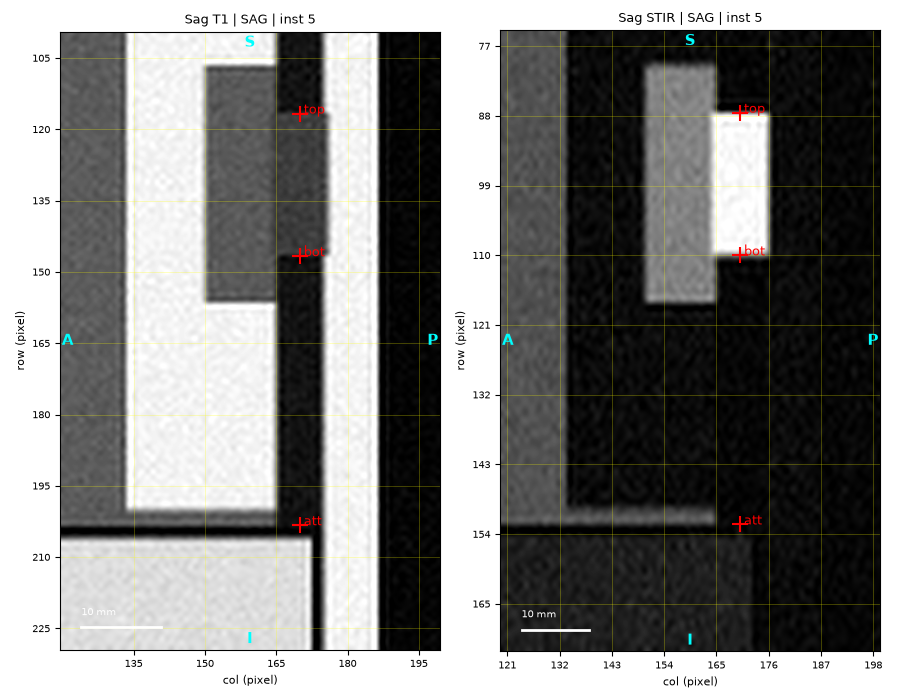

In [12]:
show(r['path'])

On T1 the band is a black line between bright fat, interrupted by grey
fluid; the grey area in front of it is the oedematous fat. On STIR the
defect is the brightest thing in the image and the fat is dark. The
markers, given in T1 pixels, land on the same anatomy on the STIR although
its pixel grid differs (rows 88/110 instead of 117/147) — they are mapped
through patient coordinates. (Panels of an orthogonal plane would only
contain the line where the two planes intersect; use `montage` or
`structure_survey` for those.)

The cross-section view is the most robust way to *see* a defect: a fixed
crop around the band, montaged over consecutive axial slices — band
present above and below, replaced by fluid in between.

instance: z (mm)  {11: 50, 12: 54, 13: 58, 14: 62, 15: 66, 16: 70, 17: 74, 18: 78, 19: 82, 20: 86, 21: 90, 22: 94}
image right = L , down = P


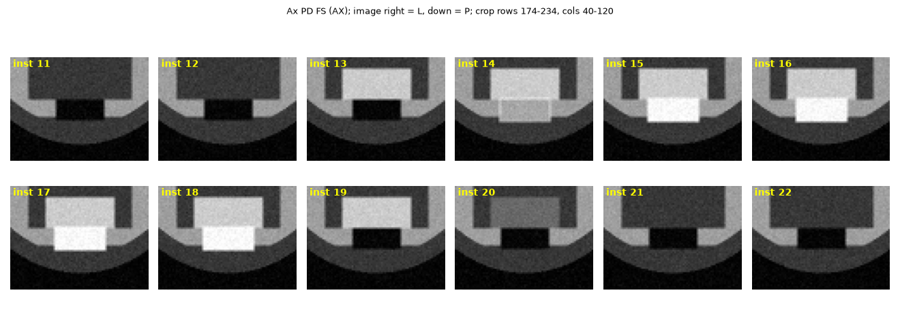

In [13]:
ctr = ax.patient_to_pixel(TRUE_MID)
rc, cc_ = int(ctr['row']), int(ctr['col'])
ax_ids = [i for i in ax.instance_numbers if 50 <= ax.center_of(i)[2] <= 94]
m = ov.radiology.montage(ax, ax_ids, crop=(rc - 30, rc + 30, cc_ - 40, cc_ + 40), ncols=6, tile_px=220,
                         out=os.path.join(WORK, 'ax_cross_section.png'))
print('instance: z (mm) ', {i: int(ax.center_of(i)[2]) for i in m['instances']})
print('image right =', m['directions']['right'], ', down =', m['directions']['down'])
show(m['path'])

The band is the dark rectangle at the bottom centre of each tile, between
suppressed (dark-grey) fat. On instances 11–13 ($z$ = 50–58 mm) and 19–22
(82–94 mm) it is present; on 14 ($z=62$, partial volume with the defect
end) it is grey, and on 15–18 (66–78 mm) it is replaced by bright fluid.
The oedema in front of it is the bright block above, from $z=58$ to 86.
Five slices at 4 mm spacing — consistent with an 18 mm defect.

`region_sheets` does the same systematically for a whole series: it finds
the body on the slice-wise maximum, covers it with overlapping square
regions and montages each region over every slice containing tissue, with
an optional lettered cell grid.

In [14]:
rs = ov.radiology.region_sheets(stir, region_mm=90, cells=3, out_prefix=os.path.join(WORK, 'stir_region'))
pd.DataFrame(rs)[['region', 'crop', 'instances', 'centre_xyz_mm']]

   region                crop                    instances      centre_xyz_mm
0       0   (0, 112, 36, 186)  [1, 2, 3, 4, 5, 6, 7, 8, 9]  [0.0, 6.6, 105.2]
1       1  (82, 194, 36, 186)  [1, 2, 3, 4, 5, 6, 7, 8, 9]   [0.0, 6.6, 39.6]

## 5. A systematic survey and a read ledger

A reader who looks only where the history points, or at whole-slice
thumbnails, misses things. `structure_survey` fixes the procedure:

* **phase 1** (no `structures`): one fluid-sensitive series per plane, cut
  into regions, every region over all its slices, each tile carrying a
  3 × 3 cell grid (`inst 5 B2`), with a JSON manifest;
* **phase 2** (`structures=[...]`): for every structure the reader has
  located, a fixed crop around it over the consecutive slices through it on
  **every** diagnostic series.

The reader answers per tile in free text. `ledger_add_read` parses
`inst N … cell …` statements, converts each cell to patient mm
(`sheet_cell_to_patient`), grades the text (3 continuity loss, 2
acute-type signal, 1 other abnormal, 0 none — negations are respected) and
appends to a JSON ledger. `ledger_hotspots` clusters abnormal reads in
space; `ledger_principal` / `draft_principal` turn the top location into a
draft finding.

In [15]:
SURVEY = os.path.join(WORK, 'survey')
sheets = ov.radiology.structure_survey(st, SURVEY)
pd.DataFrame(sheets)[['id', 'description', 'plane', 'weighting', 'crop', 'instances', 'cells']].assign(
    instances=lambda d: d.instances.map(lambda v: f'{v[0]}..{v[-1]} ({len(v)})'))

    id description plane        weighting                crop    instances  \
0  R01    Sag STIR   SAG  fluid_sensitive   (0, 112, 36, 186)     1..9 (9)   
1  R02    Sag STIR   SAG  fluid_sensitive  (82, 194, 36, 186)     1..9 (9)   
2  R03     COR obl   COR  fluid_sensitive    (0, 129, 0, 114)   1..11 (11)   
3  R04     COR obl   COR  fluid_sensitive  (102, 231, 0, 114)   1..11 (11)   
4  R05    Ax PD FS    AX  fluid_sensitive   (60, 240, 0, 160)   1..16 (16)   
5  R06    Ax PD FS    AX  fluid_sensitive   (60, 240, 0, 160)  17..31 (15)   

   cells  
0      3  
1      3  
2      3  
3      3  
4      3  
5      3  

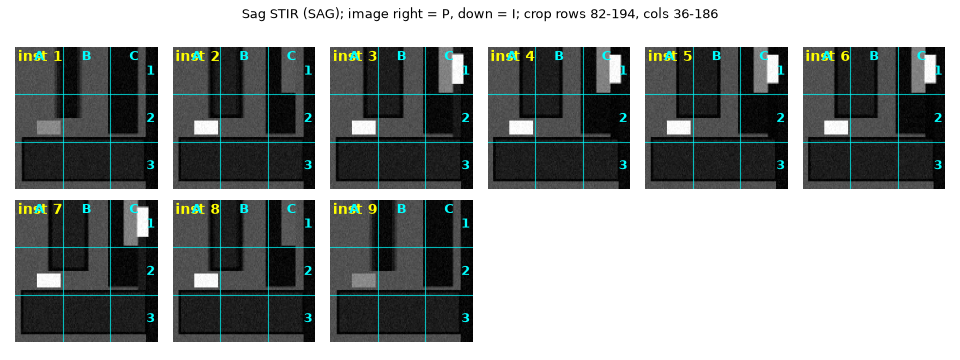

In [16]:
show(sheets[1]['path'], 1000)

A cell answer becomes a patient point — the centre of that cell on that
tile:

In [17]:
sh = sheets[1]
for cell in ('A1', 'B2', 'C3'):
    print(sh['id'], 'inst', sh['instances'][len(sh['instances']) // 2], cell, '->',
          ov.radiology.sheet_cell_to_patient(st, sh, sh['instances'][len(sh['instances']) // 2], cell))

R02 inst 5 A1 -> [0.0, -23.4, 69.5]
R02 inst 5 B2 -> [0.0, 6.6, 39.6]
R02 inst 5 C3 -> [0.0, 36.6, 9.7]


### 5.1 The reader

In practice the reads come from a radiologist or a vision model looking at
the sheets. Here we **script the reader**: for each tile it looks up what
the phantom actually contains in that tile (the ground-truth labels over the
tile's pixels), and writes what a careful reader would record — the cell
holding the finding and a short description; tiles where a lesion covers
less than ~20 mm² are read as normal (a realistic miss on grazing slices).
On **regional** sheets it describes every abnormality; on **structure**
sheets it reports only the structure the sheet is centred on, starting with
a header that names it. Each finding is its own `inst N: cell …` statement
(see pitfall 7.4 for why). The library never sees the ground truth — only
the text.

In [18]:
FINDINGS = {
    GAP: {'fluid_sensitive': 'dark band interrupted, gap filled with bright fluid between the stumps (high confidence)',
          'T1': 'dark band interrupted, gap of intermediate signal replacing the band (high confidence)'},
    EDEMA: {'fluid_sensitive': 'ill-defined hyperintense oedema in the fat (medium confidence)',
            'T1': 'fat darker than normal, intermediate signal, likely oedema (medium confidence)'},
    EFFUSION: {'fluid_sensitive': 'small fluid collection, joint effusion (medium confidence)',
               'T1': 'small collection of low signal, effusion (low confidence)'},
}


def tile_truth(series, inst, crop):
    """Ground-truth labels over a tile's pixels (what the reader 'sees')."""
    i = series.instance(inst)
    r0, r1, c0, c1 = crop
    rr, cc = np.mgrid[r0:r1, c0:c1].astype(float)
    P = i.ipp + (cc * i.ps[1])[..., None] * i.row_cos + (rr * i.ps[0])[..., None] * i.col_cos
    return labels(P), rr, cc, i.ps


def scripted_read(sheet, only=None, header=None):
    s = st[sheet['series_instance_uid']]
    w = 'T1' if s.weighting == 'T1' else 'fluid_sensitive'
    r0, r1, c0, c1 = sheet['crop']
    n = sheet['cells']
    lines = [header] if header else []
    for inst in sheet['instances']:
        lab, rr, cc, ps = tile_truth(s, inst, sheet['crop'])
        parts = []
        for f in (only or FINDINGS):
            mk = lab == f
            if mk.sum() * ps[0] * ps[1] < 20:
                continue
            col = min(n - 1, int((cc[mk].mean() - c0) / ((c1 - c0) / n)))
            row = min(n - 1, int((rr[mk].mean() - r0) / ((r1 - r0) / n)))
            parts.append(f'inst {inst}: {chr(65 + col)}{row + 1} {FINDINGS[f][w]}')
        lines += parts if parts else [f'inst {inst}: normal']      # one statement per finding
    return '\n'.join(lines)


print(scripted_read(sheets[1])[:600])

inst 1: normal
inst 2: C1 ill-defined hyperintense oedema in the fat (medium confidence)
inst 2: A2 small fluid collection, joint effusion (medium confidence)
inst 3: C1 dark band interrupted, gap filled with bright fluid between the stumps (high confidence)
inst 3: C1 ill-defined hyperintense oedema in the fat (medium confidence)
inst 3: A2 small fluid collection, joint effusion (medium confidence)
inst 4: C1 dark band interrupted, gap filled with bright fluid between the stumps (high confidence)
inst 4: C1 ill-defined hyperintense oedema in the fat (medium confidence)
inst 4: A2 small fluid 


In [19]:
LEDGER = os.path.join(WORK, 'ledger.json')
for sh in sheets:
    ov.radiology.ledger_add_read(LEDGER, st, sh, scripted_read(sh))
led = pd.DataFrame(json.load(open(LEDGER)))
print(len(led), 'reads;', (~led.normal).sum(), 'abnormal')
led.loc[~led.normal, ['sheet', 'series', 'instance', 'cell', 'xyz_mm', 'severity', 'confidence', 'text']].head(8)

96 reads; 62 abnormal


  sheet    series  instance cell              xyz_mm  severity confidence  \
1   R01  Sag STIR         2   C3   [9.0, 36.6, 75.3]         2     medium   
2   R01  Sag STIR         3   C3   [6.0, 36.6, 75.3]         3       high   
3   R01  Sag STIR         3   C3   [6.0, 36.6, 75.3]         2     medium   
4   R01  Sag STIR         4   C3   [3.0, 36.6, 75.3]         3       high   
5   R01  Sag STIR         4   C3   [3.0, 36.6, 75.3]         2     medium   
6   R01  Sag STIR         5   C3   [0.0, 36.6, 75.3]         3       high   
7   R01  Sag STIR         5   C3   [0.0, 36.6, 75.3]         2     medium   
8   R01  Sag STIR         6   C3  [-3.0, 36.6, 75.3]         3       high   

                                                text  
1  C3 ill-defined hyperintense oedema in the fat ...  
2  C3 dark band interrupted, gap filled with brig...  
3  C3 ill-defined hyperintense oedema in the fat ...  
4  C3 dark band interrupted, gap filled with brig...  
5  C3 ill-defined hyperintense 

`severity` was derived from the text: "interrupted … gap" → 3, "oedema" →
2, "effusion" → 1, using the generic triage vocabulary below (pass
`severity_terms=` to `ledger_add_read` to use another one). Now rank
locations:

In [20]:
print({k: v[:6] for k, v in ov.radiology.DEFAULT_SEVERITY_TERMS.items()})
hs = ov.radiology.ledger_hotspots(LEDGER, radius_mm=15)
hs['dist_to_true_defect_mm'] = hs.xyz_mm.map(lambda p: round(float(np.linalg.norm(np.array(p) - TRUE_MID)), 1))
hs[['xyz_mm', 'max_severity', 'n_slices_max', 'n_series_max', 'n_slices', 'n_series', 'n_planes',
    'n_normal_nearby', 'dist_to_true_defect_mm']]

{3: ['interrupt', 'discontinu', 'absent', 'gap', 'tear', 'torn'], 2: ['oedema', 'edema', 'haematoma', 'hematoma', 'blurred', 'bright core'], 1: ['fluid', 'effusion', 'thicken', 'intermediate', 'collection', 'enlarged']}


               xyz_mm  max_severity  n_slices_max  n_series_max  n_slices  \
0  [-0.0, 40.0, 72.5]             3            14             3        21   
1  [0.0, -20.9, 37.9]             1            10             2        10   

   n_series  n_planes  n_normal_nearby  dist_to_true_defect_mm  
0         3         3                0                     2.5  
1         2         2                0                    71.1  

The top hotspot — severity 3, reported on several slices of all three
surveyed series and planes — lies within a few mm of the true defect
midpoint; oedema reads in front of the band fall into the same cluster
(< 15 mm away). The effusion forms its own, severity-1 hotspot; a 3 × 3
cell is 30 mm wide, so hotspot centres are only as precise as the cells
(the defect location is refined on the phase-2 sheets). Agreement
across independent views, not a single striking read, puts a location on
top: the ranking key is (max severity, series and slices reporting it, all
series, all slices).

### 5.2 Phase 2: structure sheets

The reader now names the structures at those locations and gives a
location for each — as a patient point (the hotspot centre) or as a
`(sheet, instance, cell)` read off a regional sheet.

In [21]:
ab = led[(~led.normal) & led.text.str.contains('oedema') & ~led.text.str.contains('interrupted')
         & (led.plane == 'SAG')].iloc[0]
structures = [
    {'name': 'posterior band tendon', 'xyz_mm': hs.xyz_mm[0]},
    {'name': 'anterior fat pad', 'sheet': ab.sheet, 'instance': int(ab.instance), 'cell': ab.cell},
    {'name': 'anterior joint recess', 'xyz_mm': hs.xyz_mm[1]},
]
print('fat pad located from', ab.sheet, 'inst', ab.instance, ab.cell, '->',
      ov.radiology.sheet_cell_to_patient(st, next(s for s in sheets if s['id'] == ab.sheet), int(ab.instance), ab.cell))
sheets2 = ov.radiology.structure_survey(st, SURVEY, structures=structures)
pd.DataFrame(sheets2)[['id', 'structure', 'description', 'plane', 'crop', 'centre_instance']].assign(
    n_tiles=[len(s['instances']) for s in sheets2])

fat pad located from R01 inst 2 C3 -> [9.0, 36.6, 75.3]


     id              structure description plane                crop  \
0   S01  posterior band tendon    Sag STIR   SAG  (47, 147, 68, 200)   
1   S02  posterior band tendon     COR obl   COR   (62, 176, 0, 114)   
2   S03  posterior band tendon    Ax PD FS    AX   (80, 240, 0, 160)   
3   S04  posterior band tendon      Sag T1   SAG  (63, 195, 68, 200)   
4   S05       anterior fat pad    Sag STIR   SAG  (43, 143, 68, 200)   
5   S06       anterior fat pad     COR obl   COR   (57, 171, 0, 114)   
6   S07       anterior fat pad    Ax PD FS    AX   (80, 240, 0, 160)   
7   S08       anterior fat pad      Sag T1   SAG  (59, 191, 68, 200)   
8   S09  anterior joint recess    Sag STIR   SAG   (90, 190, 0, 132)   
9   S10  anterior joint recess     COR obl   COR   (92, 206, 0, 114)   
10  S11  anterior joint recess    Ax PD FS    AX    (0, 160, 0, 160)   
11  S12  anterior joint recess      Sag T1   SAG  (121, 253, 0, 132)   

    centre_instance  n_tiles  
0                 5        9  
1

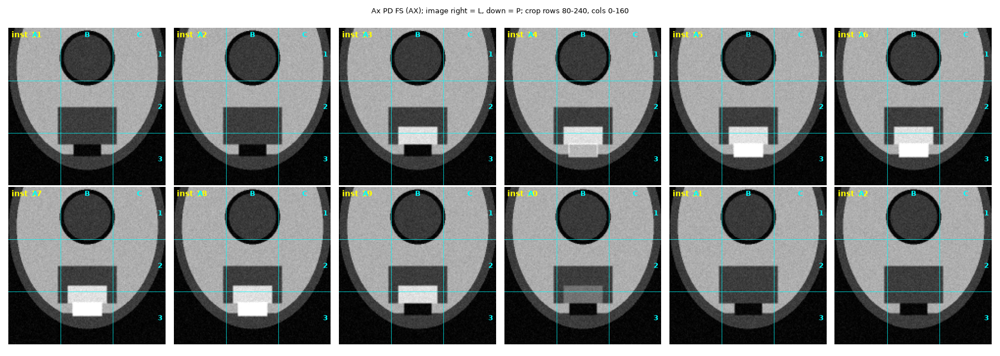

In [22]:
show(next(s for s in sheets2 if s['structure'] == 'posterior band tendon' and s['plane'] == 'AX')['path'], 1000)

In [23]:
ONLY = {'posterior band tendon': [GAP], 'anterior fat pad': [EDEMA], 'anterior joint recess': [EFFUSION]}
for sh in sheets2:
    txt = scripted_read(sh, only=ONLY[sh['structure']], header=f"Central structure: {sh['structure']}")
    ov.radiology.ledger_add_read(LEDGER, st, sh, txt)
led = pd.DataFrame(json.load(open(LEDGER)))
s2 = led[led.source == 'structure']
s2.groupby(['structure', 'series']).apply(lambda g: pd.Series({
    'tiles_read': len(g), 'abnormal_slices': int((~g.normal).sum()), 'max_severity': int(g.severity.max())}))

                                tiles_read  abnormal_slices  max_severity
structure             series                                             
anterior fat pad      Ax PD FS          12                7             2
                      COR obl           11                5             2
                      Sag STIR           9                7             2
                      Sag T1             9                7             2
anterior joint recess Ax PD FS          13                3             1
                      COR obl            1                0             0
                      Sag STIR           9                7             1
                      Sag T1             9                7             1
posterior band tendon Ax PD FS          12                5             3
                      COR obl           11                4             3
                      Sag STIR           9                5             3
                      Sag T1          

### 5.3 Concordance, principal location and the draft finding

`ledger_concordance` counts, per (structure, abnormality), how many
distinct slices and series report it. It needs the reader's
**abnormality label** for each read — `ledger_add_read` leaves
`abnormality` empty for the reader to fill — so the reader labels the
structure-sheet reads from their wording first.

In [24]:
rows = json.load(open(LEDGER))
for rr_ in rows:
    if rr_['source'] == 'structure' and not rr_['normal']:
        t_ = rr_['text']
        rr_['abnormality'] = ('discontinuity' if 'interrupted' in t_ else 'oedema' if 'oedema' in t_
                              else 'effusion' if 'effusion' in t_ else 'other')
        rr_['acute'] = rr_['abnormality'] in ('discontinuity', 'oedema')
json.dump(rows, open(LEDGER, 'w'), indent=1)
conc = ov.radiology.ledger_concordance(LEDGER)
conc[['structure', 'abnormality', 'n_slices_max_series', 'n_series', 'n_reads', 'acute_votes',
      'high_conf', 'contradicting_reads_same_slice', 'concordant']]

               structure    abnormality  n_slices_max_series  n_series  \
0       anterior fat pad         oedema                    7         4   
1  posterior band tendon  discontinuity                    5         4   
2  anterior joint recess       effusion                    7         3   

   n_reads  acute_votes  high_conf  contradicting_reads_same_slice  concordant  
0       26           26          0                               0        True  
1       19           19         19                               0        True  
2       17            0          0                               0        True  

All three findings are concordant (seen on ≥ 2 slices or ≥ 2 series) —
concordance says a finding is *real*, not which one is *principal*. The
oedema even has the most reads. `ledger_principal` summarises the top
hotspot: the structures named on sheets centred near it and, per series,
the longest run of consecutive slices read as discontinuous.

In [25]:
p = ov.radiology.ledger_principal(LEDGER)
print(json.dumps({k: p[k] for k in ('xyz_mm', 'max_severity', 'n_series', 'n_slices', 'structure_names',
                                    'discontinuity_on_consecutive_slices')}, indent=1))
pd.DataFrame({k: {'n': v['n'], 'slices': v['slices']} for k, v in p['discontinuity_runs'].items()}).T

{
 "xyz_mm": [
  -0.0,
  42.6,
  72.2
 ],
 "max_severity": 3,
 "n_series": 4,
 "n_slices": 28,
 "structure_names": [
  "posterior band tendon",
  "anterior fat pad",
  "anterior joint recess"
 ],
 "discontinuity_on_consecutive_slices": true
}


          n                slices
Sag STIR  5       [3, 4, 5, 6, 7]
Ax PD FS  5  [14, 15, 16, 17, 18]
Sag T1    5       [3, 4, 5, 6, 7]
COR obl   4          [6, 7, 8, 9]

`draft_principal` applies fixed rules on top, with terms taken from the
caller's controlled vocabulary (nothing anatomical is hard-coded): the
structure is the one with the most slices **read as discontinuous**;
discontinuity on consecutive slices in ≥ 2 series → the full-thickness
term; fluid / bright cues without scar cues → acute.

In [26]:
vocabulary = {'structure': ['posterior_band_tendon', 'anterior_fat_pad', 'anterior_joint_recess',
                            'lower_bone_block', 'upper_bone_shaft'],
              'finding_type': ['full_thickness_tear', 'partial_thickness_tear', 'tendinosis', 'effusion', 'edema'],
              'acuity': ['acute', 'chronic', 'indeterminate']}
draft = ov.radiology.draft_principal(st, LEDGER, vocabulary)
print({k: draft[k] for k in ('structure', 'finding_type', 'acuity', 'location_xyz_mm')})
print('distance of the drafted location from the true defect midpoint: %.1f mm'
      % np.linalg.norm(np.array(draft['location_xyz_mm']) - TRUE_MID))
print('basis:', draft['basis'])
pd.DataFrame(draft['measurement_candidates'])[['series', 'plane', 'weighting', 'run_slices',
                                               'instance_at_location', 'rowcol_at_location']]

{'structure': 'posterior_band_tendon', 'finding_type': 'full_thickness_tear', 'acuity': 'acute', 'location_xyz_mm': [0.0, 46.8, 72.4]}
distance of the drafted location from the true defect midpoint: 5.0 mm
basis: {'structure_votes': {'posterior_band_tendon': 19}, 'structure_names': ['posterior band tendon', 'anterior fat pad', 'anterior joint recess'], 'runs': {'Sag STIR': 5, 'Ax PD FS': 5, 'Sag T1': 5, 'COR obl': 4}, 'full_reads': 19, 'partial_reads': 0, 'acute_cues': 28, 'chronic_cues': 0}


     series plane        weighting            run_slices  \
0  Sag STIR   SAG  fluid_sensitive       [3, 4, 5, 6, 7]   
1  Ax PD FS    AX  fluid_sensitive  [14, 15, 16, 17, 18]   
2    Sag T1   SAG               T1       [3, 4, 5, 6, 7]   
3   COR obl   COR  fluid_sensitive          [6, 7, 8, 9]   

   instance_at_location rowcol_at_location  
0                     5      [97.0, 178.0]  
1                    17      [213.6, 80.0]  
2                     5     [129.3, 178.0]  
3                     9      [121.0, 57.1]  

The draft names the band, a full-thickness tear, acute — matching the
phantom (a complete, fluid-filled interruption with surrounding oedema),
located about 5 mm from the true defect midpoint (the reads' cell centres
are coarse; the measurement below places the ends precisely). `evidence` cites the nearest
instance of the two series with the longest runs. Among the measurement
candidates we measure on the **sagittal** pair: the band runs
superior–inferior, so a sagittal slice contains it lengthwise, while an
axial slice only cuts it.

## 6. Signal along the band and the gap measurement

`path_profile` traces the band between reader-placed waypoints on the
anatomic slice — a minimum-cost path through the image (dark band on T1,
`follow='dark'`), restricted to a corridor around the waypoint polyline —
and samples the same patient points on the fluid-sensitive series. The
waypoints here are where a reader would click along the band, with ±1 px
hand jitter; the last one is on the attachment.

In [27]:
def clicks(series, inst, zs, jitter=1.0):
    pts = []
    for z in zs:
        r0, c0 = to_rc(series, inst, np.array([0.0, BAND_Y, z]))
        pts.append((float(r0 + rng.uniform(-jitter, jitter)), float(c0 + rng.uniform(-jitter, jitter))))
    return pts


wps = clicks(t1, i_mid_t1, [140, 110, 50, ATTACH_Z])
prof = ov.radiology.path_profile(t1, i_mid_t1, wps, compare={'fluid': stir}, reference_mm=(0, 40))
seg = ov.radiology.abnormal_segments(prof, 'fluid_rel', factor=2.0)
print('waypoints (row, col):', np.round(wps, 1).tolist())
seg[['start_mm', 'end_mm', 'length_mm', 'start_rowcol', 'end_rowcol', 'median_rel', 'peak_rel']].round(2)

waypoints (row, col): [[16.8, 169.1], [67.2, 170.7], [167.0, 170.7], [202.9, 169.8]]


   start_mm  end_mm  length_mm start_rowcol  end_rowcol  median_rel  peak_rel
0      59.9    79.1       19.2   (116, 171)  (148, 171)       33.93     34.48

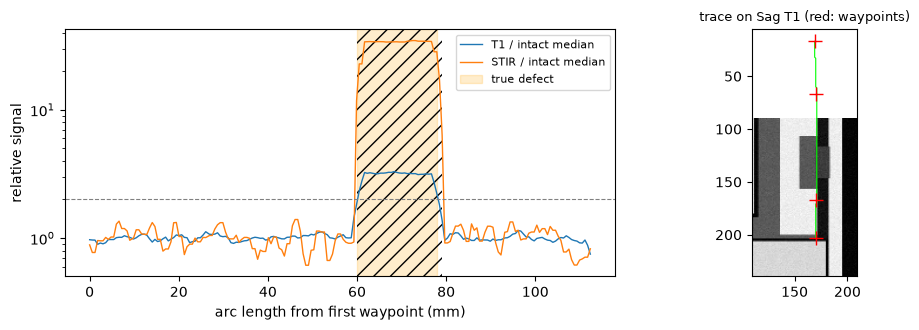

screened segment: 19.2 mm (true 18.0 mm on the midline)


In [28]:
arc_true = (140 - GAP_Z2, 140 - GAP_Z1)          # the trace starts at z = 140 and runs down
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(prof.arc_mm, prof.self_rel, lw=1, label='T1 / intact median')
axs[0].plot(prof.arc_mm, prof.fluid_rel, lw=1, label='STIR / intact median')
axs[0].axvspan(*arc_true, color='orange', alpha=0.2, label='true defect')
for _, sg in seg.iterrows():
    axs[0].axvspan(sg.start_mm, sg.end_mm, fill=False, hatch='//', ec='k', lw=0)
axs[0].axhline(2, ls='--', c='grey', lw=0.8)
axs[0].set_yscale('log'); axs[0].set_xlabel('arc length from first waypoint (mm)'); axs[0].set_ylabel('relative signal')
axs[0].legend(fontsize=8)
img = t1.pixels(i_mid_t1)
axs[1].imshow(img[90:240, 110:210], cmap='gray', extent=(109.5, 209.5, 239.5, 89.5))
axs[1].plot(prof.col, prof.row, 'lime', lw=0.8)
axs[1].plot([w[1] for w in wps], [w[0] for w in wps], 'r+', ms=10)
axs[1].set_title('trace on Sag T1 (red: waypoints)', fontsize=9)
fig.tight_layout()
display(fig)       # explicit: the notebook writes figures as files above, so nothing is auto-shown
plt.close(fig)
print('screened segment: %.1f mm (true 18.0 mm on the midline)' % seg.length_mm.max())

Both ratios sit near 1 along the intact band (the trace stayed on it — the
green line follows the dark band through the grey defect) and jump inside
the defect: about 3× on T1 (fluid is grey, the band black) and over 30× on
STIR. The STIR ratio is noisier on the intact band, where the signal is near
the noise floor. The flagged segment (hatched) is 19.2 mm against the true
18.0 mm: the 5 × 5-pixel sampling window (`halfwidth=2`, 3 mm) widens a
sharp-edged defect by about one window. The factor is a screening level for
*where to look*; the measurement below combines both contrasts.

`profile_slices` repeats the screen on every sagittal slice with the same
waypoints:

In [29]:
scr = ov.radiology.profile_slices(t1, t1.instance_numbers, wps, compare={'fluid': stir}, column='fluid_rel',
                                  reference_mm=(0, 40))
scr['slice_x_mm'] = scr.instance_number.map(lambda i: round(float(t1.center_of(i)[0]), 1))
scr[['instance_number', 'slice_x_mm', 'length_mm', 'start_mm', 'end_mm', 'median_rel']].round(1)

   instance_number  slice_x_mm  length_mm  start_mm  end_mm  median_rel
0                9        12.0        0.0       NaN     NaN         NaN
1                8         9.0        0.0       NaN     NaN         NaN
2                7         6.0       19.8      59.3    79.1         8.8
3                6         3.0       19.2      60.4    79.6        32.6
4                5         0.0       19.2      59.9    79.1        33.9
5                4        -3.0       19.2      59.9    79.1        38.7
6                3        -6.0       19.8      59.3    79.1         9.0
7                2        -9.0        0.0       NaN     NaN         NaN
8                1       -12.0        0.0       NaN     NaN         NaN

The defect segment appears on the five slices through the band
($|x| \le 6$ mm; the band is 14 mm wide) and not on $x=\pm 9, \pm 12$,
which miss it — there the "trace" runs through other tissue, a reason to
read the positive slices rather than average over all of them.

`measure_band_gap` makes it a measurement: on the chosen slice ±
`neighbours`, trace, apply the two-contrast gap criterion of §1.3, take the
longest run, convert its ends to patient mm, and report the slice with the
median gap length (robust to slices that graze or cut the band
obliquely). The reference distance is from the gap midpoint to the last
waypoint — the attachment.

In [30]:
g = ov.radiology.measure_band_gap(t1, stir, i_mid_t1, wps, neighbours=2)
per = pd.DataFrame(g['per_slice'])
per['slice_x_mm'] = per.instance.map(lambda i: round(float(t1.center_of(i)[0]), 1))
per['true_gap_mm'] = per.slice_x_mm.map(lambda x: round(float(np.diff(gap_ends(x))[0]), 1))
display(per[['instance', 'slice_x_mm', 'gap_mm', 'true_gap_mm', 'reference_distance_mm', 'trace_extended']])
ch = g['chosen']
print('chosen instance', ch['instance'], '| gap', ch['measurement_mm'], 'mm | ends', ch['landmarks_xyz_mm'],
      '| midpoint-to-attachment', ch['reference_distance_mm'], 'mm')

   instance  slice_x_mm  gap_mm  true_gap_mm  reference_distance_mm  \
0         7         6.0     0.0         18.9                    NaN   
1         6         3.0    19.2         18.2                   42.6   
2         5         0.0    18.6         18.0                   42.9   
3         4        -3.0    19.2         18.2                   42.6   
4         3        -6.0     0.0         18.9                    NaN   

   trace_extended  
0             NaN  
1             0.0  
2             0.0  
3             0.0  
4             NaN  

chosen instance 6 | gap 19.2 mm | ends [[3.0, 42.6, 80.4], [3.0, 42.6, 61.2]] | midpoint-to-attachment 42.6 mm


The three central slices measure within about 1 mm of their true gap; the
excess comes from the 5 × 5-pixel sampling window (`halfwidth=2`) and
partial volume at the defect ends. The two edge slices ($x=\pm6$ mm; the
3 mm slice spans 4.5–7.5 mm and the band ends at 7 mm) return no gap: the
slice is half band, half fat, so the *intact* band is already bright on
T1 and the defect is not 1.5 × brighter than it — the anatomic half of the
criterion fails, as it should on a grazing slice. The reported slice is the
median of the valid ones; the midpoint-to-attachment distance is within
0.5 mm of the true 43 mm.

`landmark_measurement` is the manual counterpart: the reader places the
two defect ends (and the attachment) as pixels; the function converts them
through the DICOM geometry and returns distances computed from the
*rounded* patient coordinates it reports, so anyone recomputing from the
landmarks gets the same number. Here the landmarks are taken from the
automated trace's ends, and from the truth for comparison:

In [31]:
auto = ov.radiology.landmark_measurement(t1, ch['instance'], tuple(ch['landmarks_rowcol'][0]),
                                         tuple(ch['landmarks_rowcol'][1]), reference=tuple(ch['reference_rowcol']))
i_ch = ch['instance']
xc = float(t1.center_of(i_ch)[0])
z1, z2 = gap_ends(xc)
truth = ov.radiology.landmark_measurement(t1, i_ch, to_rc(t1, i_ch, np.array([xc, BAND_Y, z2])),
                                          to_rc(t1, i_ch, np.array([xc, BAND_Y, z1])),
                                          reference=to_rc(t1, i_ch, np.array([xc, BAND_Y, ATTACH_Z])))
pd.DataFrame({'from trace ends': auto, 'from true landmarks': truth}).loc[
    ['landmarks_xyz_mm', 'measurement_mm', 'midpoint_xyz_mm', 'reference_xyz_mm', 'reference_distance_mm']]

                                              from trace ends  \
landmarks_xyz_mm       [[3.0, 42.6, 80.4], [3.0, 42.6, 61.2]]   
measurement_mm                                           19.2   
midpoint_xyz_mm                             [3.0, 42.6, 70.8]   
reference_xyz_mm                            [3.0, 42.0, 28.2]   
reference_distance_mm                                    42.6   

                                          from true landmarks  
landmarks_xyz_mm       [[3.0, 42.0, 80.1], [3.0, 42.0, 61.9]]  
measurement_mm                                           18.2  
midpoint_xyz_mm                             [3.0, 42.0, 71.0]  
reference_xyz_mm                            [3.0, 42.0, 28.0]  
reference_distance_mm                                    43.0  

### 6.1 Shading, slice choice and stump ends: `measure_band_defect`

`measure_band_gap` compares the band with its own median along the trace
and reports the median slice. Three things break that on real studies:

* **receive-coil shading.** Surface coils make the same tissue two or three
  times brighter near the coil than far from it. A band level taken over
  the whole course is then too bright at one end and too dark at the
  other, and the defect criterion fires (or fails) by position, not by
  tissue.
* **which slice.** A band a few millimetres thick is cut squarely by one or
  two slices; the others graze it. The median over all neighbours mixes
  grazing slices in.
* **where each end is.** The two stumps differ (one is usually thickened);
  a single threshold against one band level places them unevenly.

`measure_band_defect` divides the anatomic slice by its **local
bright-tissue envelope** (`band_flatfield`: fat / marrow within ~12 mm),
which leaves band darkness on a 0–1 scale independent of shading; traces
the band on the slices around the reader's slice and keeps the ones on
which the band is **most conspicuous** (darkest against its surroundings),
reporting the median defect of those; scores each point by
$\sqrt{\text{anatomic}_\text{rel}\cdot\text{fluid}_\text{rel}}$ and places
**each end** where the score falls half-way back to the level of *its own
side*; and never takes a run that reaches the reference end (the trace
leaving the band at the attachment), warning when the waypoints look
wrong.

First, shade a copy of the T1 series the way a surface coil would — the
signal falls to 35 % from top to bottom of the field of view — and look at
one row of the image before and after `band_flatfield`:

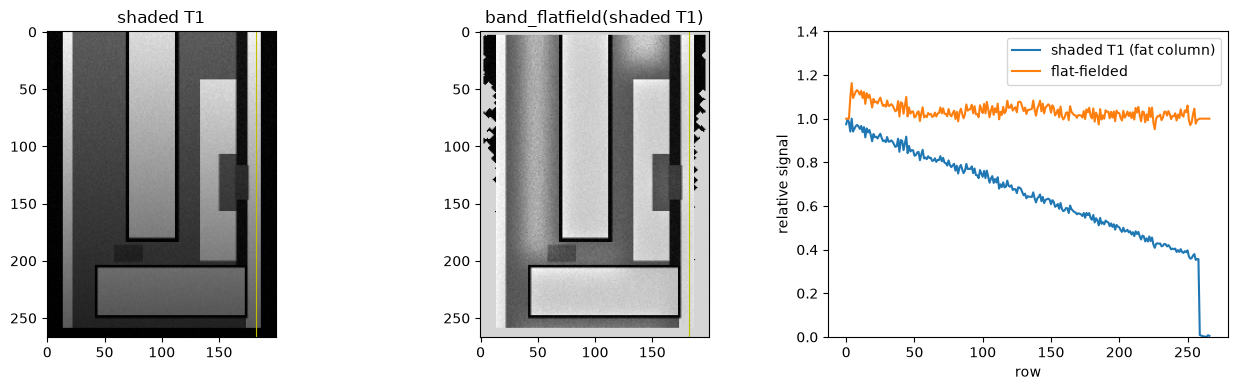

In [32]:
SHADED = os.path.join(WORK, 'study_shaded')
shutil.rmtree(SHADED, ignore_errors=True)
for s_, shade in ((t1, True), (stir, False)):
    d = os.path.join(SHADED, s_.description.replace(' ', '_'))
    os.makedirs(d)
    for inst in s_.instances:
        ds = pydicom.dcmread(inst.path)
        px = ds.pixel_array.astype(float)
        if shade:
            px *= np.linspace(1.0, 0.35, px.shape[0])[:, None]      # coil fall-off along the rows
        ds.PixelData = np.clip(px, 0, 65535).astype(np.uint16).tobytes()
        ds.save_as(os.path.join(d, os.path.basename(inst.path)))
st_sh = ov.radiology.read_dicom_study(SHADED)
t1_sh, stir_sh = st_sh['Sag T1'], st_sh['Sag STIR']

img_sh = t1_sh.pixels(i_mid_t1)
flat = ov.radiology.band_flatfield(img_sh, float(t1_sh.instance(i_mid_t1).ps[0]))
col_band = int(round(np.median([c for _, c in wps])))
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
axs[0].imshow(img_sh, cmap='gray'); axs[0].set_title('shaded T1')
axs[1].imshow(flat, cmap='gray', vmin=0, vmax=1.2); axs[1].set_title('band_flatfield(shaded T1)')
for a in axs[:2]:
    a.axvline(col_band + 12, c='y', lw=0.8)
axs[2].plot(img_sh[:, col_band + 12] / img_sh[:, col_band + 12].max(), label='shaded T1 (fat column)')
axs[2].plot(flat[:, col_band + 12], label='flat-fielded')
axs[2].set_xlabel('row'); axs[2].set_ylabel('relative signal'); axs[2].legend(); axs[2].set_ylim(0, 1.4)
plt.tight_layout(); plt.show()

Along a column of fat beside the band (yellow line) the shaded signal
falls steadily toward the bottom of the image; after `band_flatfield` it
is flat near 1 — fat reads as fat everywhere — while the band and the
defect keep their contrast against it.

Now measure the defect on the original and on the shaded study with both
functions, with the same waypoints, against the true gap on the reported
slice:

In [33]:
rows_ = []
for label_, (a_, f_) in {'original': (t1, stir), 'shaded T1': (t1_sh, stir_sh)}.items():
    g_ = ov.radiology.measure_band_gap(a_, f_, i_mid_t1, wps, neighbours=2)['chosen']
    m_ = ov.radiology.measure_band_defect(a_, f_, i_mid_t1, wps)
    for fn_, r_ in (('measure_band_gap', g_), ('measure_band_defect', m_)):
        if not r_ or not r_.get('measurement_mm'):
            rows_.append(dict(study=label_, function=fn_, gap_mm=None)); continue
        x_ = float(a_.center_of(r_['instance'])[0])
        rows_.append(dict(study=label_, function=fn_, instance=r_['instance'], slice_x_mm=round(x_, 1),
                          gap_mm=r_['measurement_mm'], true_gap_mm=round(float(np.diff(gap_ends(x_))[0]), 1),
                          to_attachment_mm=r_['reference_distance_mm'],
                          warnings='; '.join(r_.get('warnings', []))))
pd.DataFrame(rows_)

       study             function  instance  slice_x_mm  gap_mm  true_gap_mm  \
0   original     measure_band_gap         6         3.0    19.2         18.2   
1   original  measure_band_defect         4        -3.0    17.4         18.2   
2  shaded T1     measure_band_gap         6         3.0    18.6         18.2   
3  shaded T1  measure_band_defect         6         3.0    17.4         18.2   

   to_attachment_mm warnings  
0              42.6           
1              42.9           
2              42.9           
3              42.9           

In [34]:
m = ov.radiology.measure_band_defect(t1_sh, stir_sh, i_mid_t1, wps)
pd.DataFrame(m['slices']).assign(slice_x_mm=lambda d: d.instance.map(lambda i: round(float(t1_sh.center_of(i)[0]), 1)))

   instance  conspicuity  found  measurement_mm  reference_distance_mm  \
0         7     0.177348   True            19.2                   42.6   
1         6     0.080522   True            17.4                   42.9   
2         5     0.080944   True            17.4                   42.9   
3         4     0.080237   True            17.4                   42.9   
4         3     0.177748   True            18.6                   42.9   

   slice_x_mm  
0         6.0  
1         3.0  
2         0.0  
3        -3.0  
4        -6.0  

On this clean phantom both functions land within about 1 mm of the true
gap and 0.5 mm of the 43 mm attachment distance, shaded or not; the
per-slice table shows why the reported slice is a central one — the band
is most conspicuous (lowest normalised band signal, ≈ 0.08) on the three
slices through its middle and twice as bright on the grazing $x=\pm6$ mm
slices, which are left out. On real studies the two diverge: on an ankle
MRI with a radiologist-reported Achilles rupture, 17 waypoint sets placed
by agents gave a gap *and* attachment distance inside the radiologist's
range in 1 of 15 cases with `measure_band_gap` and 6–9 of 17 with
`measure_band_defect` (the misses were waypoints that stopped short of
the attachment).

The remaining failure is the reader's: the reference distance runs to the
**last waypoint**, so it must be on the attachment. The function cannot
know where the attachment is, but it can tell when the waypoints are
implausible — here the last point is put just below the defect instead of
on the bone:

In [35]:
wps_short = clicks(t1, i_mid_t1, [140, 110, GAP_Z1 - 4])
m_short = ov.radiology.measure_band_defect(t1, stir, i_mid_t1, wps_short)
print('gap', m_short.get('measurement_mm'), 'mm | to "attachment"', m_short.get('reference_distance_mm'), 'mm')
for w_ in m_short['warnings']:
    print('WARNING:', w_)

gap None mm | to "attachment" None mm


No defect is reported — the abnormal run now touches the trace's end, and
a run at the reference end is never taken as a gap between two stumps
(on real studies such runs are usually the trace leaving the band into fat
or bone at the attachment) — and the warnings say what to fix. Act on
warnings by moving the waypoint (render the whole course of the structure
so the attachment is in view), not by tuning parameters.

## 7. Pitfalls

### 7.1 A structure vote that counts every abnormal read

The obvious way to pick the principal structure — the one with the most
abnormal reads — picks the **oedematous fat pad**: oedema extends over
more slices than the defect it surrounds. `draft_principal` counts only
reads that describe a **discontinuity** (severity 3 and continuity-loss
wording), one vote per slice.

In [32]:
led = pd.DataFrame(json.load(open(LEDGER)))
s2 = led[(led.source == 'structure') & ~led.normal]
naive = s2.drop_duplicates(['structure', 'series', 'instance']).groupby('structure').size().sort_values(ascending=False)
print('naive vote (abnormal slices per structure):'); print(naive.to_string())
print('\nnaive principal structure:', naive.index[0])
print('draft_principal votes (discontinuity slices only):', draft['basis']['structure_votes'])
print('draft_principal structure:', draft['structure'])

naive vote (abnormal slices per structure):
structure
anterior fat pad         26
posterior band tendon    19
anterior joint recess    17

naive principal structure: anterior fat pad
draft_principal votes (discontinuity slices only): {'posterior_band_tendon': 19}
draft_principal structure: posterior_band_tendon


Oedema, effusion and "thickened" reads are real findings, but secondary;
the discontinuity is the lesion. A vote that lets them count rewards the
structure with the largest reactive change around a lesion, not the
lesion.

### 7.2 A waypoint inside the defect truncates the gap

If the reader's first click lands inside the defect (easy: the gap looks
like part of the band's course on a fluid-sensitive image), the trace
starts mid-gap and any profile-based measurement can only see the part of
the gap below the click.

In [33]:
wps_bad = clicks(t1, i_mid_t1, [72, 50, ATTACH_Z])          # first click 8 mm below the top of the defect
prof_bad = ov.radiology.path_profile(t1, i_mid_t1, wps_bad, compare={'fluid': stir})
prof_bad['gap_score'] = np.minimum(prof_bad.self_rel / 1.5, prof_bad.fluid_rel / 2.0)
naive_seg = ov.radiology.abnormal_segments(prof_bad, 'gap_score', factor=1.0, min_length_mm=3)
print('profile from a mid-gap first waypoint: gap %.1f mm, starting at arc %.1f mm (the trace start)'
      % (naive_seg.length_mm.max(), naive_seg.start_mm.iloc[0]))
g_bad = ov.radiology.measure_band_gap(t1, stir, i_mid_t1, wps_bad, neighbours=2)
print('measure_band_gap with the same waypoints: gap %.1f mm, trace extended %d time(s), defect_at_trace_end=%s'
      % (g_bad['chosen']['measurement_mm'], g_bad['chosen']['trace_extended'], g_bad['chosen']['defect_at_trace_end']))

profile from a mid-gap first waypoint: gap 10.8 mm, starting at arc 0.0 mm (the trace start)


measure_band_gap with the same waypoints: gap 19.2 mm, trace extended 1 time(s), defect_at_trace_end=False


A second, quieter failure: with the band's *median* as the intact
reference, a trace that is mostly defect has a "normal" level that is
already fluid, and nothing stands out. Give `reference_mm` an interval on
the intact band, or start the trace well outside the defect.

`measure_band_gap` detects a run that touches the free end of the trace
and prolongs the trace straight beyond it (up to twice), which recovers
the full gap here. It cannot repair a trace that never reaches intact band
on the *attachment* side — keep the last waypoint on the attachment.

### 7.3 Pixels are not millimetres — and rows are not columns

The STIR has 0.8 mm between rows and 0.6 mm between columns. Reading the
defect ends off the STIR and converting the pixel distance with the
wrong spacing — the column spacing, an "isotropic" average, or another
series' pixel size — gives the wrong length.

In [34]:
i_mid_stir = stir.patient_to_pixel(TRUE_MID)['instance_number']
a_rc = to_rc(stir, i_mid_stir, np.array([0.0, BAND_Y, GAP_Z2]))
b_rc = to_rc(stir, i_mid_stir, np.array([0.0, BAND_Y, GAP_Z1]))
d_px = np.hypot(b_rc[0] - a_rc[0], b_rc[1] - a_rc[1])
ps_stir = stir.instance(i_mid_stir).ps
print('STIR PixelSpacing (row, col):', ps_stir.tolist(), '| defect ends (row, col):', a_rc, b_rc)
print('pixel distance:', round(d_px, 1), 'px')
print('x column spacing (%.1f, wrong axis):   %.1f mm' % (ps_stir[1], d_px * ps_stir[1]))
print('x mean spacing   (%.1f, "isotropic"): %.2f mm' % (ps_stir.mean(), d_px * ps_stir.mean()))
m_ok = ov.radiology.landmark_measurement(stir, i_mid_stir, a_rc, b_rc)
print('landmark_measurement (DICOM geometry): %.1f mm   (truth 18.0 mm)' % m_ok['measurement_mm'])

STIR PixelSpacing (row, col): [0.8, 0.6] | defect ends (row, col): (np.float64(87.5), np.float64(170.0)) (np.float64(110.0), np.float64(170.0))
pixel distance: 22.5 px
x column spacing (0.6, wrong axis):   13.5 mm
x mean spacing   (0.7, "isotropic"): 15.75 mm
landmark_measurement (DICOM geometry): 18.0 mm   (truth 18.0 mm)


The defect runs along the image's columns (superior–inferior), i.e.
across **rows**, so the row spacing (0.8 mm) applies; using 0.6 mm
shortens it by 25 %. `pixel_to_patient` / `landmark_measurement` apply
$\Delta_r$ along $\mathbf{c}$ and $\Delta_c$ along $\mathbf{r}$ for every
series, and measure between patient points, so oblique slices and
different resolutions need no special care.

### 7.4 One statement per finding

`ledger_add_read` grades a whole `inst N` statement and gives every cell
named in it that grade. A reader who lists two findings of one tile in one
sentence makes the minor one inherit the major one's severity:

In [35]:
# a sagittal survey tile that contains both the defect and the effusion
sh, inst = next((s, i) for s in sheets if s['plane'] == 'SAG' for i in s['instances']
                if 'interrupted' in scripted_read(dict(s, instances=[i]), only=[GAP])
                and 'effusion' in scripted_read(dict(s, instances=[i]), only=[EFFUSION]))
print('sheet', sh['id'], 'inst', inst)
one_line = scripted_read(dict(sh, instances=[inst])).replace(f'\ninst {inst}:', ';')
sep_lines = scripted_read(dict(sh, instances=[inst]))
tmp = os.path.join(WORK, 'tmp_ledger.json')
for label, txt in (('one sentence', one_line), ('one statement per finding', sep_lines)):
    if os.path.exists(tmp):
        os.remove(tmp)
    ent = ov.radiology.ledger_add_read(tmp, st, sh, txt)
    print(f'{label:26s}', [(e['cell'], e['severity'], e['text'][3:28]) for e in ent])

sheet R02 inst 3
one sentence               [('A2', 3, 'dark band interrupted, ga'), ('C1', 3, 'dark band interrupted, ga')]
one statement per finding  [('C1', 3, 'dark band interrupted, ga'), ('C1', 2, 'ill-defined hyperintense '), ('A2', 1, 'small fluid collection, j')]


Written as one sentence, the effusion cell gets severity 3 and the text of
the tear: a severity-3 "lesion" appears some 70 mm from the real one and
competes with it in `ledger_hotspots`. One statement per finding keeps
each cell's own grade.

## 8. Summary

| Quantity | Truth | Recovered |
|---|---|---|

In [36]:
summary = pd.DataFrame([
    ('planes of 4 diagnostic series', 'SAG, SAG, AX, COR (oblique)', ', '.join(st.table().query('~is_localizer').plane)),
    ('fluid-sensitive series', 'Sag STIR, Ax PD FS, COR obl',
     ', '.join(st.table().query('weighting == "fluid_sensitive" and ~is_localizer').description)),
    ('principal structure', 'posterior band tendon', draft['structure']),
    ('finding / acuity', 'complete, fluid-filled / acute', f"{draft['finding_type']} / {draft['acuity']}"),
    ('location error (mm)', '0', f"{np.linalg.norm(np.array(draft['location_xyz_mm']) - TRUE_MID):.1f}"),
    ('gap on measured slice (mm)', f"{float(np.diff(gap_ends(xc))[0]):.1f}", f"{ch['measurement_mm']}"),
    ('gap midpoint to attachment (mm)', f"{float(np.mean(gap_ends(xc))) - ATTACH_Z:.1f}", f"{ch['reference_distance_mm']}"),
], columns=['quantity', 'truth', 'recovered'])
print(f'total runtime {time.time() - T0:.0f} s')
summary

total runtime 23 s


                          quantity                           truth  \
0    planes of 4 diagnostic series     SAG, SAG, AX, COR (oblique)   
1           fluid-sensitive series     Sag STIR, Ax PD FS, COR obl   
2              principal structure           posterior band tendon   
3                 finding / acuity  complete, fluid-filled / acute   
4              location error (mm)                               0   
5       gap on measured slice (mm)                            18.2   
6  gap midpoint to attachment (mm)                            43.0   

                     recovered  
0            SAG, SAG, AX, COR  
1  Sag STIR, Ax PD FS, COR obl  
2        posterior_band_tendon  
3  full_thickness_tear / acute  
4                          5.0  
5                         19.2  
6                         42.6  

**Caveats.** The phantom is deliberately simple — a straight band, a clean
fluid-filled defect, a scripted reader that sees exactly what is there. On
real studies the reader (human or model) is the weakest link: reads of the
same location disagree between views, structures get mis-named, and
curved bands need waypoints every few centimetres. The survey and ledger
exist so that such disagreement is visible and outvoted, but they cannot
create a read that was never made. Thresholds (`factor`, `anat_factor`)
are screening levels for where to look; the images decide.

## 9. References

* DICOM PS3.3, *Information Object Definitions*, C.7.6.2 Image Plane Module (Image Position / Orientation (Patient), Pixel Spacing). NEMA. https://dicom.nema.org/medical/dicom/current/output/html/part03.html#sect_C.7.6.2
* Mason, D. *et al.* pydicom: an open source DICOM library in Python. https://github.com/pydicom/pydicom
* Bloch, F. (1946). Nuclear induction. *Phys. Rev.* 70:460–474. https://doi.org/10.1103/PhysRev.70.460
* Bydder, G. M. & Young, I. R. (1985). MR imaging: clinical use of the inversion recovery sequence. *J. Comput. Assist. Tomogr.* 9:659–675.
* Gudbjartsson, H. & Patz, S. (1995). The Rician distribution of noisy MRI data. *Magn. Reson. Med.* 34:910–914. https://doi.org/10.1002/mrm.1910340618
* Stanisz, G. J. *et al.* (2005). T1, T2 relaxation and magnetization transfer in tissue at 3T. *Magn. Reson. Med.* 54:507–512. https://doi.org/10.1002/mrm.20605
* Bitar, R. *et al.* (2006). MR pulse sequences: what every radiologist wants to know but is afraid to ask. *RadioGraphics* 26:513–537. https://doi.org/10.1148/rg.262055063
* Dijkstra, E. W. (1959). A note on two problems in connexion with graphs. *Numer. Math.* 1:269–271. https://doi.org/10.1007/BF01386390 (minimum-cost path, as in `skimage.graph.route_through_array`)